In [ ]:
!date

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import anndata
import scanpy as sc

from scipy.stats import pearsonr

In [ ]:
projdir = '/u/project/cluo/terencew/igvf/2023_YR2/multiome/'
donors = sorted(list(np.loadtxt(f'{projdir}/txt/donors.txt', dtype=str)))
tmp_order = ['Start', 'Sendai', 'Delayed', 'Fail1', 'Inter1',  'Inter2', 'Fail2', 'IPS']
clusts = [f'{x}_{y}' for x,y in zip(np.repeat(tmp_order, len(donors)), np.tile(donors, len(tmp_order)))]

### desired figures:
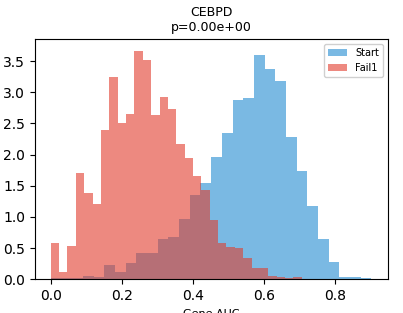

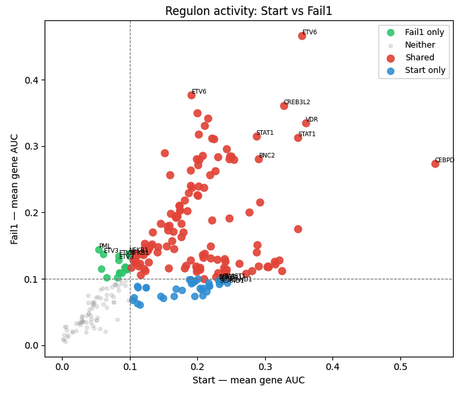

### 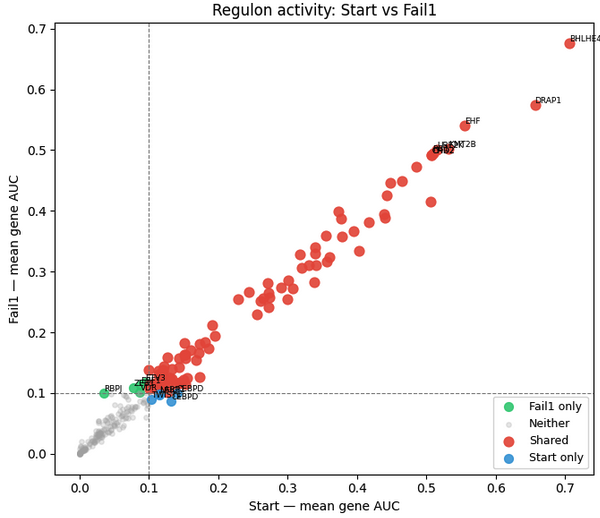

### pseudobulk merged AUC

In [ ]:
indir = f'{projdir}/csv/gene_networks/scenic/fail1_start'
merged = pd.read_csv(f'{indir}/merged_auc.csv', sep='\t', index_col=0)
merged.shape

In [ ]:
merged.head()

In [ ]:
### 
# # Compute global mean (all clusters) for background comparison

In [ ]:
ax = sns.scatterplot(data=merged, x='Start_RNA', y='Fail1_RNA')

In [ ]:
ax = sns.scatterplot(data=merged, x='Start_ATAC', y='Fail1_ATAC')

In [ ]:
x = merged['Start_RNA']
y = merged['Fail1_RNA']
pearsonr(x,y)

In [ ]:
x = merged['Start_ATAC']
y = merged['Fail1_ATAC']
pearsonr(x,y)

In [ ]:
n_regs = merged.shape[0]
mods = ['RNA', 'ATAC']

In [ ]:
start_auc = pd.DataFrame(pd.concat([merged['Start_RNA'], merged['Start_ATAC']]))
start_auc.columns = ['start_AUC']

fail1_auc = pd.DataFrame(pd.concat([merged['Fail1_RNA'], merged['Fail1_ATAC']]))
fail1_auc.columns = ['fail1_AUC']

to_plot = pd.concat([start_auc, fail1_auc], axis=1)
to_plot['mod'] = np.repeat(mods, n_regs)
to_plot.head()

In [ ]:
sns.scatterplot(to_plot, x='start_AUC', y='fail1_AUC', hue='mod')

In [ ]:
outdir = '/u/project/cluo/terencew/igvf/2023_YR2/final_figures/csv/figure3'
to_plot.to_csv(f'{outdir}/scenic_pseudo_auc.csv', sep='\t')

### histogram of differences

In [ ]:
merged['gene_diff'] = merged['Start_RNA'] - merged['Fail1_RNA']
merged['abs_gene_diff'] = merged['gene_diff'].abs()

merged['region_diff'] = merged['Start_ATAC'] - merged['Fail1_ATAC']
merged['abs_region_diff'] = merged['region_diff'].abs()

merged.head()

In [ ]:
fig, ax = plt.subplots(1, figsize=(5, 5))
ax.hist(data=merged, x='abs_gene_diff');
ax.hist(data=merged, x='abs_region_diff');

### RUNX

In [ ]:
mask = ['RUNX1' in x for x in merged.index]
tmp_merged = merged[mask]
tmp_merged.shape

In [ ]:
tmp_merged.head()

### cell-level AUC

In [ ]:
gene_adata = sc.read_h5ad(f'{projdir}/h5ad/joint/scenic/merged_gene_auc.h5ad')
gene_adata

In [ ]:
region_adata = sc.read_h5ad(f'{projdir}/h5ad/joint/scenic/merged_region_auc.h5ad')
region_adata

In [ ]:
tmp_start_gene = gene_adata[gene_adata.obs['coarse_v7'] == 'Start']
tmp_fail1_gene = gene_adata[gene_adata.obs['coarse_v7'] == 'Fail1']
tmp_start_region = region_adata[region_adata.obs['coarse_v7'] == 'Start']
tmp_fail1_region = region_adata[region_adata.obs['coarse_v7'] == 'Fail1']

In [ ]:
n = 8
regulons = merged['abs_gene_diff'].sort_values(ascending=False)[:n].index
regulons[:5]

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(12,7))
axes = axes.flatten()

rna_reg_list = []

for i,ax in enumerate(axes):
    tmp_reg = regulons[i]
    reg_start_gene = np.ravel(tmp_start_gene[:,tmp_start_gene.var.index == tmp_reg].X)
    reg_fail1_gene = np.ravel(tmp_fail1_gene[:,tmp_fail1_gene.var.index == tmp_reg].X)
    ax.hist(reg_start_gene, bins=30, alpha=0.6, label='Start', color='#3498db', density=False)
    ax.hist(reg_fail1_gene, bins=30, alpha=0.6, label='Fail1', color='#e74c3c', density=False)

    ax.set_title(tmp_reg)
    ax.legend(fontsize=7)
    
    ###
    tmp_start = pd.DataFrame(reg_start_gene)
    tmp_start.columns = ['AUC']
    tmp_start['cluster'] = 'Start'
    tmp_start['regulon'] = tmp_reg
    tmp_fail1 = pd.DataFrame(reg_fail1_gene)
    tmp_fail1.columns = ['AUC']
    tmp_fail1['cluster'] = 'Fail1'
    tmp_fail1['regulon'] = tmp_reg
    tmp_merged = pd.concat([tmp_start, tmp_fail1])
    rna_reg_list.append(tmp_merged)

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(12,7))
axes = axes.flatten()

atac_reg_list = []

for i,ax in enumerate(axes):
    tmp_reg = regulons[i]
    reg_start_region = np.ravel(tmp_start_region[:,tmp_start_region.var.index == tmp_reg].X)
    reg_fail1_region = np.ravel(tmp_fail1_region[:,tmp_fail1_region.var.index == tmp_reg].X)
    ax.hist(reg_start_region, bins=30, alpha=0.6, label='Start', color='#3498db', density=True)
    ax.hist(reg_fail1_region,  bins=30, alpha=0.6, label='Fail1', color='#e74c3c', density=True)
    ax.set_title(tmp_reg)
    ax.legend(fontsize=7)
    
    ###
    tmp_start = pd.DataFrame(reg_start_region)
    tmp_start.columns = ['AUC']
    tmp_start['cluster'] = 'Start'
    tmp_start['regulon'] = tmp_reg
    tmp_fail1 = pd.DataFrame(reg_fail1_region)
    tmp_fail1.columns = ['AUC']
    tmp_fail1['cluster'] = 'Fail1'
    tmp_fail1['regulon'] = tmp_reg
    tmp_merged = pd.concat([tmp_start, tmp_fail1])
    atac_reg_list.append(tmp_merged)

In [ ]:
merged_rna = pd.concat(rna_reg_list)
merged_atac = pd.concat(atac_reg_list)
merged_rna['mod'] = 'RNA'
merged_atac['mod'] = 'ATAC'
final_merged = pd.concat([merged_rna, merged_atac])
final_merged['final_regulon'] = [x.split('_')[0] for x in final_merged['regulon']]
final_merged.shape

In [ ]:
final_merged

In [ ]:
outdir = '/u/project/cluo/terencew/igvf/2023_YR2/final_figures/csv/figure3'
final_merged.to_csv(f'{outdir}/scenic_singlecell_auc.csv', sep='\t')

### more

In [ ]:
n = 64
regulons = merged['abs_gene_diff'].sort_values(ascending=False)[:n].index
fig, axes = plt.subplots(8, 8, figsize=(36,21))
axes = axes.flatten()

rna_reg_list = []

for i,ax in enumerate(axes):
    tmp_reg = regulons[i]
    reg_start_gene = np.ravel(tmp_start_gene[:,tmp_start_gene.var.index == tmp_reg].X)
    reg_fail1_gene = np.ravel(tmp_fail1_gene[:,tmp_fail1_gene.var.index == tmp_reg].X)
    ax.hist(reg_start_gene, bins=30, alpha=0.6, label='Start', color='#3498db', density=False)
    ax.hist(reg_fail1_gene, bins=30, alpha=0.6, label='Fail1', color='#e74c3c', density=False)

    ax.set_title(tmp_reg)
    ax.legend(fontsize=7)
    
    ###
    tmp_start = pd.DataFrame(reg_start_gene)
    tmp_start.columns = ['AUC']
    tmp_start['cluster'] = 'Start'
    tmp_start['regulon'] = tmp_reg
    tmp_fail1 = pd.DataFrame(reg_fail1_gene)
    tmp_fail1.columns = ['AUC']
    tmp_fail1['cluster'] = 'Fail1'
    tmp_fail1['regulon'] = tmp_reg
    tmp_merged = pd.concat([tmp_start, tmp_fail1])
    rna_reg_list.append(tmp_merged)
    
plt.subplots_adjust(hspace=0.4, wspace=0.4)

In [ ]:
!date